In [7]:
import numpy as np
import matplotlib.pyplot as plt
from tabulate import tabulate
from sboxes.loader import load as load_sbox
from evaluation.uniformity import ddt
from evaluation.avalanche_criterion import print_avalanche_summary, plot_avalanche_matrix
from evaluation.markov_chains.basic_markov_chain import DifferentialMarkovChain

from evaluation.markov_chains.basic_markov_chain import create_transition_matrix, create_transition_matrix_from_sbox

In [8]:
def test_sbox_markov(sbox, epsilon=1e-4, r_values=[1,2,5,10]):
    """
    Ejecuta pruebas de Markov en la S-Box:
     - Doble estocasticidad, irreducibilidad, aperiodicidad, ergodicidad
     - Mixing times iterativo y espectral
     - TV distance y max probability
     - Gráfica TV distance vs pasos
    """
    print(f"\n### Pruebas MarkovChain para {type(sbox).__name__}")
    P = create_transition_matrix_from_sbox(sbox)
    chain = DifferentialMarkovChain(P)

    # Propiedades
    print("Doble estocástica:", chain.is_doubly_stochastic())
    print("Irreducible:", chain.is_irreducible())
    print("Aperiodic:", chain.is_aperiodic())
    print("Ergódica:", chain.is_ergodic())

    # Mixing times
    tau_iter = chain.mixing_time_iterative(epsilon)
    tau_spec = chain.mixing_time_spectral(epsilon)
    print(f"Mixing time iterativo (ε={epsilon}): {tau_iter}")
    print(f"Mixing time espectral  (ε={epsilon}): {tau_spec}")

    # TV distance y max probability
    for r in r_values:
        tv = chain.tv_distance(r)
        mp = chain.max_probability(r)
        print(f"Paso {r}: TV_distance={tv:.6f}, max_probability={mp:.6f}")

    # Gráfica TV distance vs r
    rs = list(range(1, max(r_values)+1))
    tvs = [chain.tv_distance(r) for r in rs]
    plt.figure(figsize=(6,4))
    plt.plot(rs, tvs, marker='o')
    plt.title(f"TV Distance vs Steps: {type(sbox).__name__}")
    plt.xlabel("Steps r")
    plt.ylabel("TV Distance")
    plt.grid(True)
    plt.show()

## 5 bits

In [3]:
import json
path = 'sboxes/data/nuestro 5.v3.json'
data = json.load(open(path))
print(data["table"])
lista = list(map(lambda x: hex(x), data["table"]))
print(lista)
print(len(data["table"]))

[17, 8, 3, 24, 19, 2, 13, 31, 6, 30, 10, 22, 20, 21, 12, 0, 1, 7, 15, 27, 16, 23, 26, 18, 29, 28, 11, 5, 9, 4, 14, 25]
['0x11', '0x8', '0x3', '0x18', '0x13', '0x2', '0xd', '0x1f', '0x6', '0x1e', '0xa', '0x16', '0x14', '0x15', '0xc', '0x0', '0x1', '0x7', '0xf', '0x1b', '0x10', '0x17', '0x1a', '0x12', '0x1d', '0x1c', '0xb', '0x5', '0x9', '0x4', '0xe', '0x19']
32


In [10]:
# Cargar ASCON S-Box
fides5 = load_sbox('sboxes/data/wage_WGP.json')
print('# S-Box FIDES 5')

# S-Box FIDES 5


## 1. Avalanche Criterion
SAC promedio general: 0.519
Desviación estándar máxima: 0.080
╒═════╤═══════════╤═══════════╕
│     │   Avg SAC │   Std SAC │
╞═════╪═══════════╪═══════════╡
│ In0 │     0.518 │     0.023 │
├─────┼───────────┼───────────┤
│ In1 │     0.54  │     0.049 │
├─────┼───────────┼───────────┤
│ In2 │     0.504 │     0.066 │
├─────┼───────────┼───────────┤
│ In3 │     0.531 │     0.044 │
├─────┼───────────┼───────────┤
│ In4 │     0.513 │     0.058 │
├─────┼───────────┼───────────┤
│ In5 │     0.513 │     0.08  │
├─────┼───────────┼───────────┤
│ In6 │     0.513 │     0.076 │
╘═════╧═══════════╧═══════════╛


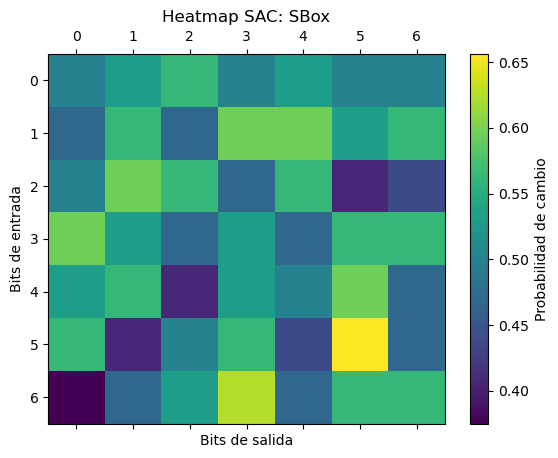

In [11]:
# 1. Avalanche Criterion
print('## 1. Avalanche Criterion')
print_avalanche_summary(fides5)
plot_avalanche_matrix(fides5)

In [12]:
# 2. Pruebas de Cadena de Markov
print('## 2. Pruebas de la Cadena de Markov')
test_sbox_markov(fides5)

## 2. Pruebas de la Cadena de Markov

### Pruebas MarkovChain para SBox
Doble estocástica: True
Irreducible: True


KeyboardInterrupt: 

In [ ]:
from sboxes.loader import load as load_sbox
from evaluation.markov_chains.test_markov_chain import test_sbox_markov, create_transition_matrix

\
# Prueba con FIDES S-Box
print("=== Pruebas de Markov Chain para FIDES 5 ===")
fides5 = load_sbox("sboxes/ascon.json")
test_sbox_markov(fides5)



=== Pruebas de Markov Chain para FIDES 5 ===


FileNotFoundError: [Errno 2] No such file or directory: 'sboxes/ascon.json'

## Markov Chain Tests (ASCON)
Doble estocástica: True
Irreducible: True
Aperiodic: True
Ergódica: True
Mixing time (iterativo): 11
Mixing time (espectral): 14
r=1: TV=0.8710, max_prob=0.2500
r=2: TV=0.4294, max_prob=0.1094
r=5: TV=0.0189, max_prob=0.0351
r=10: TV=0.0001, max_prob=0.0323


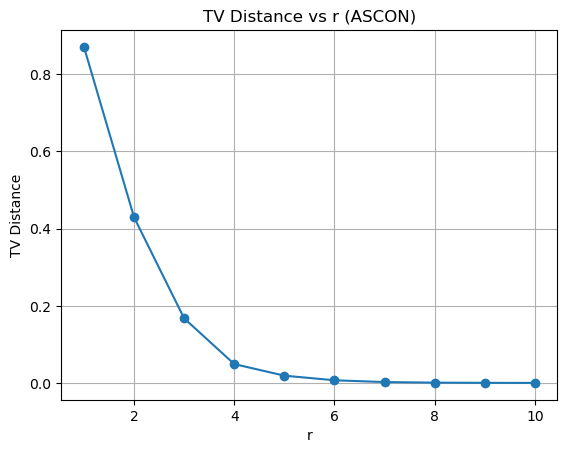

In [ ]:
# Version anterior, que se debe actualizar# 2) Pruebas de Cadena de Markov para fides5
print('## Markov Chain Tests (fides5)')
P_fides5 = create_transition_matrix(fides5)
chain_fides5 = DifferentialMarkovChain(P_fides5)
print('Doble estocástica:', chain_fides5.is_doubly_stochastic())
print('Irreducible:', chain_fides5.is_irreducible())
print('Aperiodic:', chain_fides5.is_aperiodic())
print('Ergódica:', chain_fides5.is_ergodic())
print('Mixing time (iterativo):', chain_fides5.mixing_time_iterative(1e-4))
print('Mixing time (espectral):', chain_fides5.mixing_time_spectral(1e-4))
# Distancias y max prob
for r in [1,2,5,10]:
    print(f'r={r}: TV={chain_fides5.tv_distance(r):.4f}, max_prob={chain_fides5.max_probability(r):.4f}')
# Grafica TV vs r
rs = list(range(1,11))
tvs = [chain_fides5.tv_distance(r) for r in rs]
plt.plot(rs, tvs, marker='o')
plt.title('TV Distance vs r (FIDES 5)')
plt.xlabel('r')
plt.ylabel('TV Distance')
plt.grid(True)
plt.show()

### S-boxes encontradas

In [ ]:
# 3) Definición de las dos últimas S-Boxes 5x5 del archivo
# Últimas dos tablas 5x5 
sbox5_a = [9,0,14,5,21,27,2,8,24,19,12,13,31,11,30,16,7,20,18,29,4,6,3,17,1,25,28,15,10,22,23,26]
sbox5_b = [23,21,10,5,27,19,29,8,12,1,26,16,31,28,11,20,30,4,15,24,13,3,9,2,25,6,18,0,7,14,17,22]

from sboxes.sbox import SBox
# Crear instancias SBox jitclass
sbox_a = SBox(5,5,np.array(sbox5_a,dtype=np.uint64))
sbox_b = SBox(5,5,np.array(sbox5_b,dtype=np.uint64))

### 5x5-A
Avalanche Criterion:
SAC promedio general: 0.510
Desviación estándar máxima: 0.146
╒═════╤═══════════╤═══════════╕
│     │   Avg SAC │   Std SAC │
╞═════╪═══════════╪═══════════╡
│ In0 │     0.5   │     0.112 │
├─────┼───────────┼───────────┤
│ In1 │     0.6   │     0.146 │
├─────┼───────────┼───────────┤
│ In2 │     0.55  │     0.061 │
├─────┼───────────┼───────────┤
│ In3 │     0.425 │     0.1   │
├─────┼───────────┼───────────┤
│ In4 │     0.475 │     0.146 │
╘═════╧═══════════╧═══════════╛


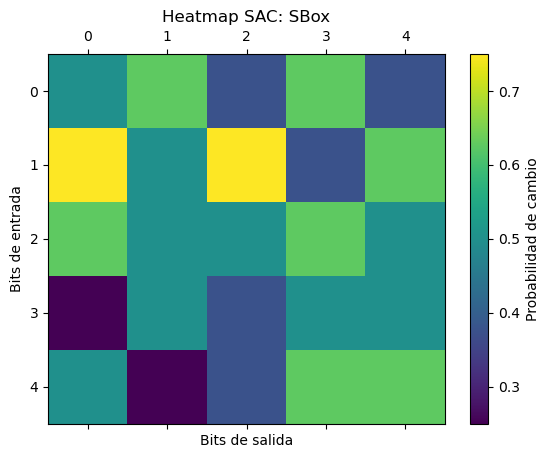

Markov Tests:
Ergódica: True
Mixing time iters: 8
Mixing time spec: 12
r=1: TV=0.6452, max_prob=0.1875
r=2: TV=0.1607, max_prob=0.0664
r=5: TV=0.0032, max_prob=0.0328
r=10: TV=0.0000, max_prob=0.0323

### 5x5-B
Avalanche Criterion:
SAC promedio general: 0.495
Desviación estándar máxima: 0.127
╒═════╤═══════════╤═══════════╕
│     │   Avg SAC │   Std SAC │
╞═════╪═══════════╪═══════════╡
│ In0 │     0.575 │     0.127 │
├─────┼───────────┼───────────┤
│ In1 │     0.45  │     0.1   │
├─────┼───────────┼───────────┤
│ In2 │     0.525 │     0.094 │
├─────┼───────────┼───────────┤
│ In3 │     0.5   │     0.112 │
├─────┼───────────┼───────────┤
│ In4 │     0.425 │     0.1   │
╘═════╧═══════════╧═══════════╛


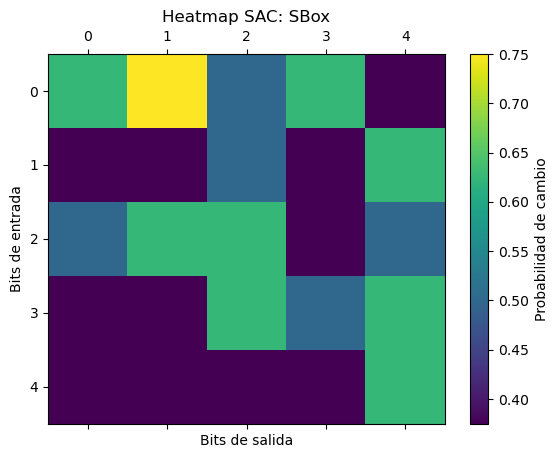

Markov Tests:
Ergódica: True
Mixing time iters: 8
Mixing time spec: 12
r=1: TV=0.6129, max_prob=0.1250
r=2: TV=0.1442, max_prob=0.0625
r=5: TV=0.0023, max_prob=0.0328
r=10: TV=0.0000, max_prob=0.0323



In [ ]:
# 4) Pruebas Avalanche y Markov para S-Boxes 5x5
for name, sbox in [('5x5-A', sbox_a), ('5x5-B', sbox_b)]:
    print(f'### {name}')
    print('Avalanche Criterion:')
    print_avalanche_summary(sbox)
    plot_avalanche_matrix(sbox)
    print('Markov Tests:')
    P5 = create_transition_matrix(sbox)
    chain5 = DifferentialMarkovChain(P5)
    print('Ergódica:', chain5.is_ergodic())
    print('Mixing time iters:', chain5.mixing_time_iterative(1e-4))
    print('Mixing time spec:', chain5.mixing_time_spectral(1e-4))
    rs = [1,2,5,10]
    for r in rs:
        print(f'r={r}: TV={chain5.tv_distance(r):.4f}, max_prob={chain5.max_probability(r):.4f}')
    print()


## Comparative TV distance & Max probability
|   r |   TV_ascon |   MP_ascon |   TV_A |   MP_A |   TV_B |   MP_B |
|-----|------------|------------|--------|--------|--------|--------|
|   1 |     0.871  |     0.25   | 0.6452 | 0.1875 | 0.6129 | 0.125  |
|   2 |     0.4294 |     0.1094 | 0.1607 | 0.0664 | 0.1442 | 0.0625 |
|   3 |     0.1675 |     0.0566 | 0.0428 | 0.0398 | 0.0368 | 0.0396 |
|   4 |     0.0489 |     0.0417 | 0.0112 | 0.0346 | 0.0089 | 0.0343 |
|   5 |     0.0189 |     0.0351 | 0.0032 | 0.0328 | 0.0023 | 0.0328 |
|   6 |     0.007  |     0.0334 | 0.0009 | 0.0324 | 0.0006 | 0.0324 |
|   7 |     0.0023 |     0.0326 | 0.0002 | 0.0323 | 0.0001 | 0.0323 |
|   8 |     0.0009 |     0.0324 | 0.0001 | 0.0323 | 0      | 0.0323 |
|   9 |     0.0003 |     0.0323 | 0      | 0.0323 | 0      | 0.0323 |
|  10 |     0.0001 |     0.0323 | 0      | 0.0323 | 0      | 0.0323 |
|  11 |     0      |     0.0323 | 0      | 0.0323 | 0      | 0.0323 |
|  12 |     0      |     0.0323 | 0      | 0.

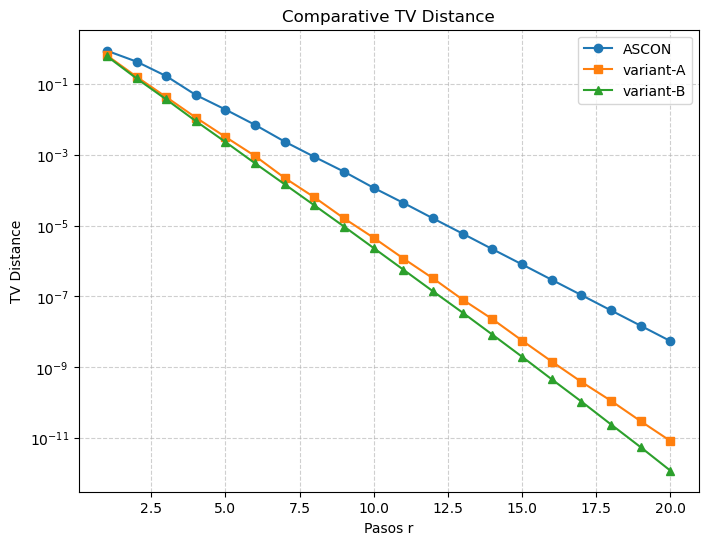

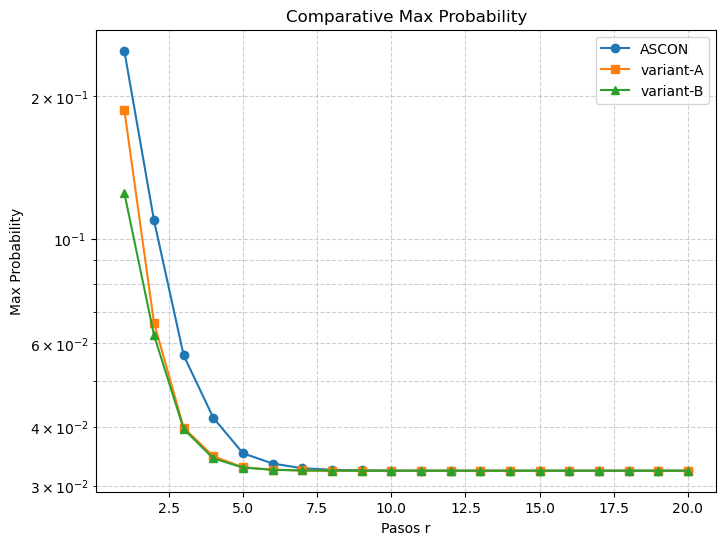

In [ ]:
# 5) Comparación conjunta de TV distance y Max probability
print('## Comparative TV distance & Max probability')
rs = list(range(1, 21))
# Datos ASCON
# (Reactiva chain_ascon de sección previa)
tvs_ascon = [chain_ascon.tv_distance(r) for r in rs]
mps_ascon = [chain_ascon.max_probability(r) for r in rs]
# Datos SBox A
P_a = create_transition_matrix(sbox_a)
chain_a = DifferentialMarkovChain(P_a)
tvs_a = [chain_a.tv_distance(r) for r in rs]
mps_a = [chain_a.max_probability(r) for r in rs]
# Datos SBox B
P_b = create_transition_matrix(sbox_b)
chain_b = DifferentialMarkovChain(P_b)
tvs_b = [chain_b.tv_distance(r) for r in rs]
mps_b = [chain_b.max_probability(r) for r in rs]

# Tabla comparativa
comp_table = []
for i, r in enumerate(rs):
    comp_table.append([
        r,
        f'{tvs_ascon[i]:.4f}', f'{mps_ascon[i]:.4f}',
        f'{tvs_a[i]:.4f}', f'{mps_a[i]:.4f}',
        f'{tvs_b[i]:.4f}', f'{mps_b[i]:.4f}'
    ])
print(tabulate(comp_table,
               headers=['r', 'TV_ascon','MP_ascon','TV_A','MP_A','TV_B','MP_B'],
               tablefmt='github'))

# Gráfica comparativa de TV distance
plt.figure(figsize=(8,6))
plt.plot(rs, tvs_ascon, label='ASCON', marker='o')
plt.plot(rs, tvs_a, label='variant-A', marker='s')
plt.plot(rs, tvs_b, label='variant-B', marker='^')
plt.xlabel('Pasos r')
plt.ylabel('TV Distance')
plt.yscale("log")
plt.title('Comparative TV Distance')
plt.legend()
plt.grid(True, which="both", ls="--", alpha=0.6)
plt.show()

# Gráfica comparativa de Max probability
plt.figure(figsize=(8,6))
plt.plot(rs, mps_ascon, label='ASCON', marker='o')
plt.plot(rs, mps_a, label='variant-A', marker='s')
plt.plot(rs, mps_b, label='variant-B', marker='^')
plt.xlabel('Pasos r')
plt.ylabel('Max Probability')
plt.yscale("log")
plt.title('Comparative Max Probability')
plt.legend()
plt.grid(True, which="both", ls="--", alpha=0.6)
plt.show()


# Version anterior, que se debe actualizar

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from sboxes.loader import load as load_sbox
from evaluation.uniformity import ddt
from evaluation.markov_chains.basic_markov_chain import DifferentialMarkovChain
from evaluation.avalanche_criterion import print_avalanche_summary, plot_avalanche_matrix, IdentitySBox



box = AsconSBox()
#vec    = np.fromiter((box.apply(i) for i in range(256)), dtype=np.uint8)

# 8×8  ⇒  n_in = n_out = 8
vec = np.array([box.apply(i) for i in range(1 << box.input_size)], dtype=np.uint8)

P = transition_matrix(vec, box.input_size, box.output_size, skip_zero=True)

# 3. la cadena
chain = DifferentialMarkovChain(P, init="uniform")

print("∥πP-π∥₁   =", np.linalg.norm(chain.stationary_distribution() @ P
                                    - chain.stationary_distribution(), 1))
print("gap       =", chain.spectral_gap())
for r in range(1, 5):
    print(f"r={r}:  max P^r = {chain.max_probability(r):.3e}, "
          f"dTV = {chain.tv_distance(r):.3e}")
print("mezcla ε=2⁻²⁰ en", chain.mixing_time(eps=2**-20), "pasos")


NameError: name 'AsconSBox' is not defined

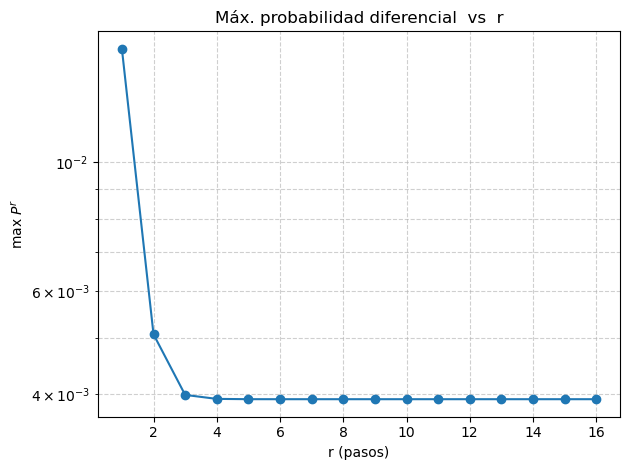

In [ ]:
# ---  máxima probabilidad diferencial ---
plt.figure()
plt.plot(r_vals, max_prob, marker="o")
plt.yscale("log")
plt.title("Máx. probabilidad diferencial  vs  r")
plt.xlabel("r (pasos)")
plt.ylabel("max $P^r$")
plt.grid(True, which="both", ls="--", alpha=0.6)
plt.tight_layout()
plt.show()


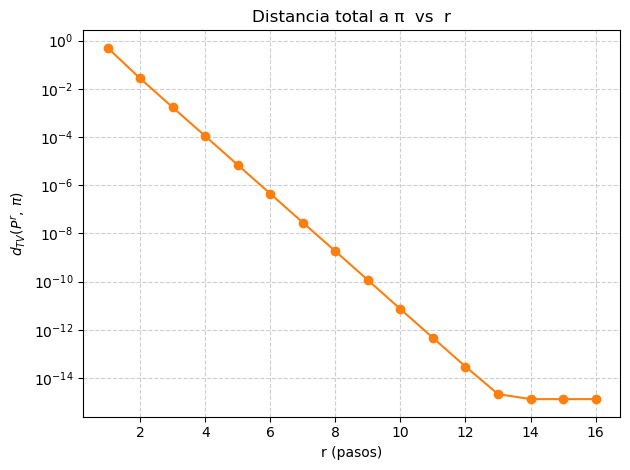

In [ ]:
# --- distancia total a la distribución estacionaria ---
plt.figure()
plt.plot(r_vals, tv_dist, marker="o", color="tab:orange")
plt.yscale("log")
plt.title("Distancia total a π  vs  r")
plt.xlabel("r (pasos)")
plt.ylabel("$d_{TV}(P^r,\\,π)$")
plt.grid(True, which="both", ls="--", alpha=0.6)
plt.tight_layout()
plt.show()

r |  maxProb   |  dTV
------------------------------
 0| 1.0000e+00 | 9.6774e-01
 1| 1.2500e-01 | 7.4194e-01
 2| 6.2500e-02 | 1.7440e-01
 3| 4.2969e-02 | 6.4894e-02
 4| 3.7231e-02 | 2.9403e-02
 5| 3.3218e-02 | 8.7389e-03
 6| 3.2690e-02 | 3.4965e-03
 7| 3.2458e-02 | 1.4216e-03
 8| 3.2324e-02 | 5.1848e-04
 9| 3.2283e-02 | 1.9509e-04
10| 3.2267e-02 | 7.2310e-05
11| 3.2261e-02 | 2.6837e-05
12| 3.2259e-02 | 9.9359e-06
13| 3.2259e-02 | 3.6520e-06
14| 3.2258e-02 | 1.3490e-06
15| 3.2258e-02 | 4.9749e-07
16| 3.2258e-02 | 1.8331e-07


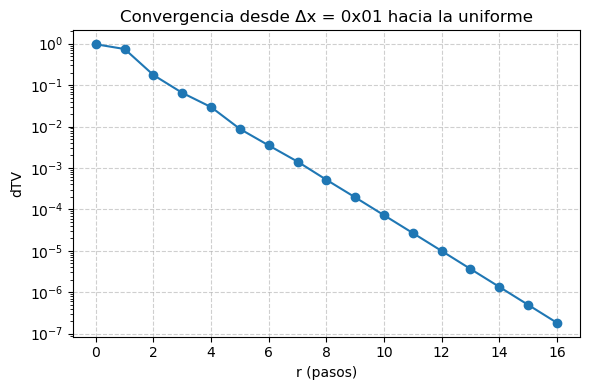

In [ ]:

box = AsconSBox()
#vec    = np.fromiter((box.apply(i) for i in range(256)), dtype=np.uint8)

# 8×8  ⇒  n_in = n_out = 8
vec = np.array([box.apply(i) for i in range(1 << box.input_size)], dtype=np.uint8)

P = transition_matrix(vec, box.input_size, box.output_size, skip_zero=True)

k = P.shape[0]
uniform_pi = np.full(k, 1/k)
pi0 = np.zeros(k); 
pi0[0]=1.

R_MAX=16; 
tv=[]; mp=[]; cur=pi0.copy()
for r in range(R_MAX+1):
    tv.append(0.5*np.abs(cur-uniform_pi).sum())
    mp.append(cur.max())
    if r<R_MAX: cur = cur @ P

print("r |  maxProb   |  dTV")
print("-"*30)
for r,(p,d) in enumerate(zip(mp,tv)):
    print(f"{r:2d}| {p:10.4e} | {d:10.4e}")

plt.figure(figsize=(6,4))
plt.plot(range(R_MAX+1), tv, marker="o")
plt.yscale("log"); plt.grid(True, ls="--", alpha=0.6)
plt.xlabel("r (pasos)"); plt.ylabel("dTV")
plt.title("Convergencia desde Δx = 0x01 hacia la uniforme")
plt.tight_layout()
plt.show()

## Extraccion de sboxes optimizadas

   Nombre     | Mixing time | Spectral gap
---------------------------------------------
Clásico      |          22 | 0.6312
Ascon #1     |          19 | 0.7525
Ascon #2     |          20 | 0.7288
Ascon #3     |          20 | 0.7146
Ascon #4     |          19 | 0.7635


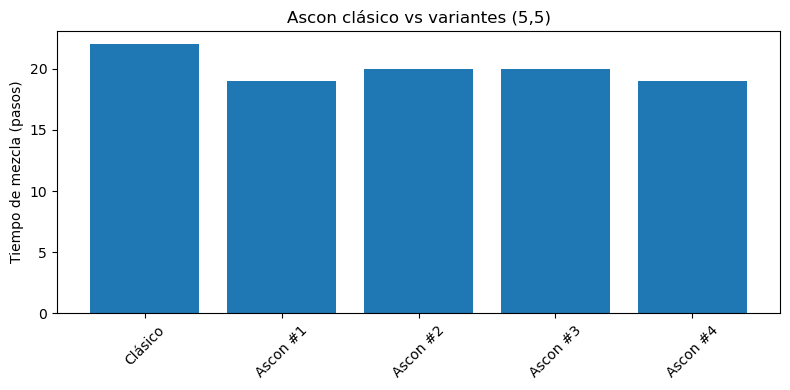

In [ ]:
import sys
from pathlib import Path
import importlib.util

# 1) Cargar dinámicamente sbox.py
project_root = Path().resolve()
sbox_path = project_root / "sbox.py"
spec = importlib.util.spec_from_file_location("sbox", str(sbox_path))
sbox_mod = importlib.util.module_from_spec(spec)
spec.loader.exec_module(sbox_mod)
AsconSBox = sbox_mod.AsconSBox
AESSBox  = sbox_mod.AESSBox

# 2) Imports de la cadena
import ast
import numpy as np
import matplotlib.pyplot as plt
from juan_duarte.markov_utils import transition_matrix
from juan_duarte.markov_chain import DifferentialMarkovChain

# 3) Genérico para cargar tus tablas (5,5)
class GenericSBox(AsconSBox):
    def __init__(self, table, input_size, output_size):
        super().__init__()
        self.table = table
        self.input_size = input_size
        self.output_size = output_size

def load_ascon_variants(path, target_shape=(5,5)):
    variants = []
    with open(path, 'r') as f:
        for line in f:
            if not line.startswith(str(target_shape)):
                continue
            _, list_repr = line.split(':', 1)
            table = ast.literal_eval(list_repr.strip())
            variants.append(GenericSBox(table, input_size=5, output_size=5))
    return variants

# 4) Evaluador genérico
def evaluate_sbox(sb, eps=2**-20):
    vec = np.array([sb.apply(i) for i in range(1 << sb.input_size)], dtype=np.uint8)
    P   = transition_matrix(vec, sb.input_size, sb.output_size, skip_zero=True)
    chain = DifferentialMarkovChain(P, init="uniform")
    return chain.mixing_time(eps=eps), chain.spectral_gap()

# 5) Ejecutar pruebas
ruta_txt       = "results.txt"                   # Ajusta según ubicación
ascon_variants = load_ascon_variants(ruta_txt)

mix_classic, gap_classic = evaluate_sbox(AsconSBox())
results = [("Clásico", mix_classic, gap_classic)]

for idx, sb in enumerate(ascon_variants, 1):
    mix, gap = evaluate_sbox(sb)
    results.append((f"Ascon #{idx}", mix, gap))

# 6) Mostrar resultados
print("   Nombre     | Mixing time | Spectral gap")
print("---------------------------------------------")
for name, mix, gap in results:
    print(f"{name:12} | {mix:11} | {gap:.4f}")

# 7) Gráfico comparativo
labels    = [r[0] for r in results]
mix_times = [r[1] for r in results]

plt.figure(figsize=(8,4))
plt.bar(labels, mix_times)
plt.xticks(rotation=45)
plt.ylabel("Tiempo de mezcla (pasos)")
plt.title("Ascon clásico vs variantes (5,5)")
plt.tight_layout()
plt.show()


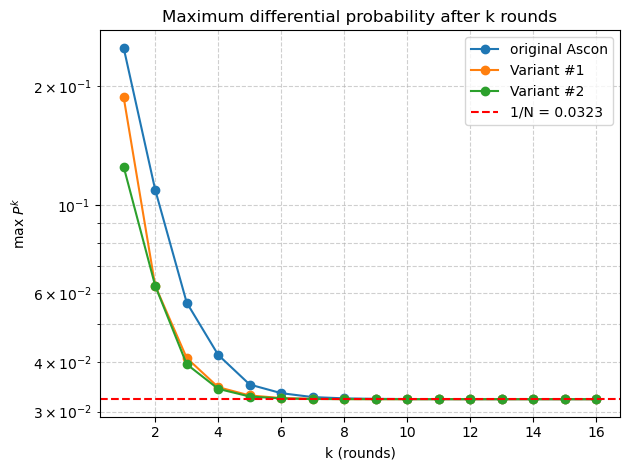

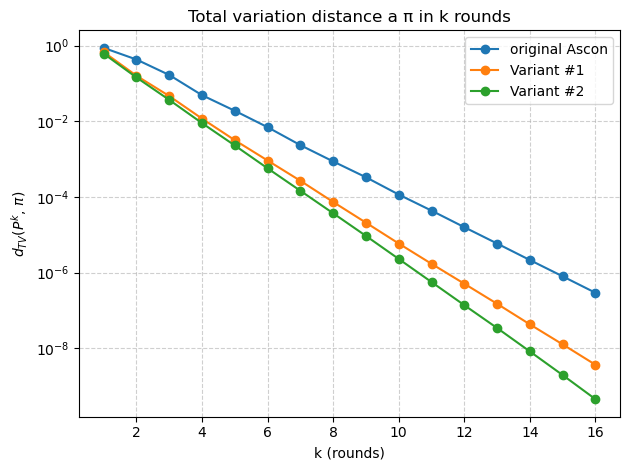

In [ ]:
import sys
from pathlib import Path
import importlib.util
import ast
import numpy as np
import matplotlib.pyplot as plt
from juan_duarte.markov_utils import transition_matrix
from juan_duarte.markov_chain import DifferentialMarkovChain

n = box.input_size
threshold = 1/(2**n - 1)

# 1) Carga dinámica de sbox.py
root = Path().resolve()
spec = importlib.util.spec_from_file_location("sbox", str(root / "sbox.py"))
sbox_mod = importlib.util.module_from_spec(spec)
spec.loader.exec_module(sbox_mod)
AsconSBox = sbox_mod.AsconSBox

# 2) Genérico para variantes (5,5)
class GenericSBox(AsconSBox):
    def __init__(self, table):
        super().__init__()           # inicializa como AsconSBox
        self.table = table           # sustituye la tabla
        self.input_size = 5
        self.output_size = 5

# 3) Carga de tablas optimizadas (5,5)
def load_variants(path, target_shape="(5, 5)"):
    variants = []
    with open(path, 'r') as f:
        for line in f:
            if line.startswith(target_shape):
                _, lst = line.split(':', 1)
                table = ast.literal_eval(lst.strip())
                variants.append(GenericSBox(table))
    return variants

variants = load_variants("results.txt")  # o "sboxes.txt" según corresponda
variants = variants[-2:]

# 4) Función para calcular métricas
def compute_metrics(sb, R_MAX=16):
    vec = np.array([sb.apply(i) for i in range(1 << sb.input_size)], dtype=np.uint8)
    P   = transition_matrix(vec, sb.input_size, sb.output_size, skip_zero=True)
    chain = DifferentialMarkovChain(P, init="uniform")
    r_vals   = np.arange(1, R_MAX+1)
    max_prob = [chain.max_probability(r) for r in r_vals]
    tv_dist  = [chain.tv_distance(r)     for r in r_vals]
    return r_vals, np.array(max_prob), np.array(tv_dist)

# 5) Recolectar datos para original y variantes
r_vals, max_orig, tv_orig = compute_metrics(AsconSBox())
metrics = [("original Ascon", max_orig, tv_orig)]
for idx, sb in enumerate(variants, 1):
    _, mp, tv = compute_metrics(sb)
    metrics.append((f"Variant #{idx}", mp, tv))

# 6) Gráficas comparativas
plt.figure()
for label, mp, _ in metrics:
    plt.plot(r_vals, mp, marker="o", label=label)
plt.axhline(threshold, color="red", linestyle="--",
            label=f"1/N = {threshold:.4f}")
plt.yscale("log")
plt.title("Maximum differential probability after k rounds")
plt.xlabel("k (rounds)")
plt.ylabel("max $P^k$")
plt.grid(True, which="both", ls="--", alpha=0.6)
plt.legend()
plt.tight_layout()
plt.show()

plt.figure()
for label, _, tv in metrics:
    plt.plot(r_vals, tv, marker="o", label=label)
plt.yscale("log")
plt.title("Total variation distance a π in k rounds")
plt.xlabel("k (rounds)")
plt.ylabel("$d_{TV}(P^k,\\,π)$")
plt.grid(True, which="both", ls="--", alpha=0.6)
plt.legend()
plt.tight_layout()
plt.show()


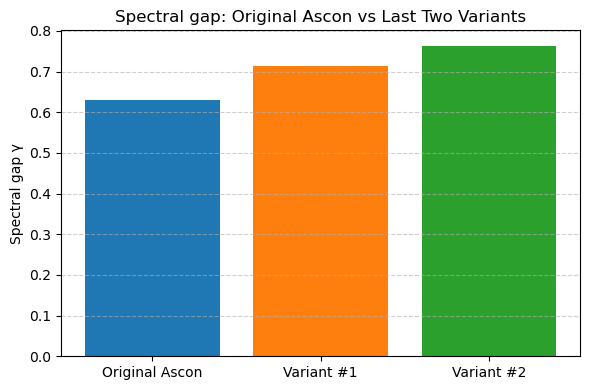

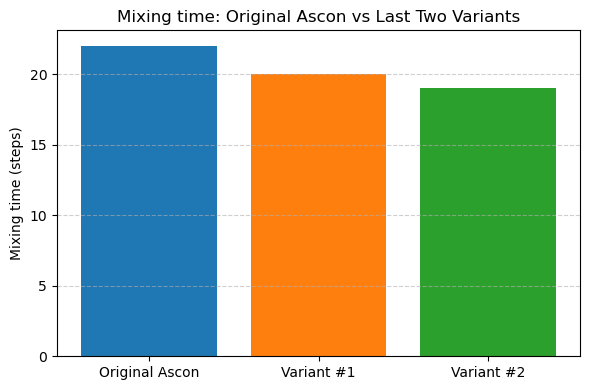

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# --- Supongamos que `variants` ya contiene solo las dos últimas GenericSBox ---
# variants = load_variants("results.txt")[-2:]

# Función auxiliar para calcular mixing time y spectral gap
def eval_sb(sb):
    vec = np.array([sb.apply(i) for i in range(1 << sb.input_size)], dtype=np.uint8)
    P   = transition_matrix(vec, sb.input_size, sb.output_size, skip_zero=True)
    chain = DifferentialMarkovChain(P, init="uniform")
    return chain.mixing_time(eps=2**-20), chain.spectral_gap()

# Evaluamos las dos variantes
names = []
mix_times = []
gaps = []
for idx, sb in enumerate(variants, start=1):
    mix, gap = eval_sb(sb)
    names.append(f"Variant #{idx}")
    mix_times.append(mix)
    gaps.append(gap)

# --- 1) Evaluate original and last two variants ---
mix_orig, gap_orig = eval_sb(AsconSBox())

# Assume `variants` is a list of your optimized GenericSBox objects;
# already sliced to contain only the last two variants.
mix_var1, gap_var1 = eval_sb(variants[0])
mix_var2, gap_var2 = eval_sb(variants[1])

# --- 2) Prepare data for plotting ---
names      = ["Original Ascon", "Variant #1", "Variant #2"]
mix_times  = [mix_orig, mix_var1, mix_var2]
spect_gaps = [gap_orig,  gap_var1,  gap_var2]

# --- 3) Plot Spectral Gap Comparison ---
plt.figure(figsize=(6,4))
plt.bar(names, spect_gaps, color=['C0','C1','C2'])
plt.ylabel("Spectral gap γ")
plt.title("Spectral gap: Original Ascon vs Last Two Variants")
plt.grid(axis='y', ls='--', alpha=0.6)
plt.tight_layout()
plt.show()

# --- 4) Plot Mixing Time Comparison ---
plt.figure(figsize=(6,4))
plt.bar(names, mix_times, color=['C0','C1','C2'])
plt.ylabel("Mixing time (steps)")
plt.title("Mixing time: Original Ascon vs Last Two Variants")
plt.grid(axis='y', ls='--', alpha=0.6)
plt.tight_layout()
plt.show()